# Q2: Random Forests on Heart Disease (tabular) and Intel Images
Breiman (2001): forest error is bounded by (mean correlation between trees) x (1 - strength^2)/strength^2.
Strong individual trees + low correlation (bagging + random feature subsets) => lower generalization error.

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

N_TREES = [1, 10, 50, 100, 300]

In [2]:
def run(Xtr, Xte, ytr, yte, name):
    accs = []
    for n in N_TREES:
        accs.append(accuracy_score(yte, RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1).fit(Xtr, ytr).predict(Xte)))
    plt.plot(N_TREES, accs, marker="o"); plt.xlabel("n_estimators"); plt.ylabel("Test accuracy")
    plt.title(f"{name}: accuracy vs trees"); plt.grid(); plt.savefig(f"results/q2_{name}_trees.png", dpi=120); plt.show()
    rows = []
    for mname, m in {"Decision Tree": DecisionTreeClassifier(random_state=42),
                     "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
                     "SVM (RBF)": SVC()}.items():
        t = time.time(); m.fit(Xtr, ytr); tt = time.time() - t
        rows.append({"Model": mname, "Test acc": round(accuracy_score(yte, m.predict(Xte)), 4), "Train time (s)": round(tt, 3)})
    print(dict(zip(N_TREES, np.round(accs, 4)))); return pd.DataFrame(rows)

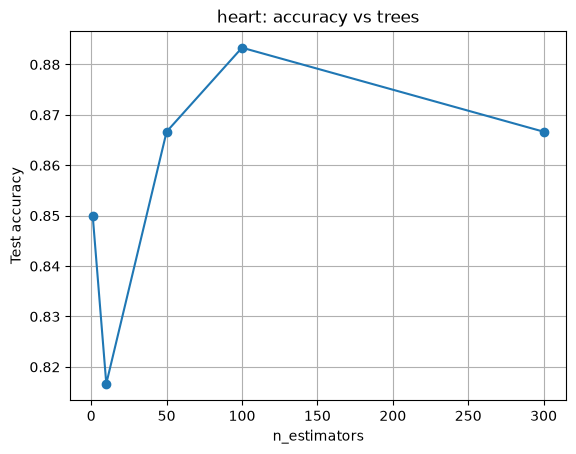

{1: np.float64(0.85), 10: np.float64(0.8167), 50: np.float64(0.8667), 100: np.float64(0.8833), 300: np.float64(0.8667)}


,Model,Test acc,Train time (s)
0,Decision Tree,0.7833,0.003
1,Random Forest,0.8833,0.264
2,SVM (RBF),0.9000,0.004


In [3]:
heart = pd.read_csv("../ASSIGNMENT02/heart_cleveland_upload.csv")
X, y = heart.drop(columns="condition"), heart["condition"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)                      # preprocessing: standardize (helps SVM)
heart_results = run(sc.transform(Xtr), sc.transform(Xte), ytr, yte, "heart")
heart_results

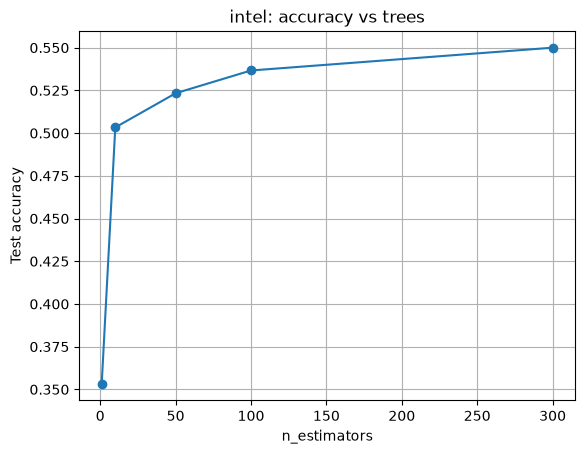

{1: np.float64(0.3533), 10: np.float64(0.5033), 50: np.float64(0.5233), 100: np.float64(0.5367), 300: np.float64(0.55)}


,Model,Test acc,Train time (s)
0,Decision Tree,0.3567,3.583
1,Random Forest,0.5367,1.134
2,SVM (RBF),0.5667,3.386


In [4]:
# Download from Kaggle: puneet6060/intel-image-classification  -> unzip into ../ASSIGNMENT02/
cands = [Path("../ASSIGNMENT02/seg_train/seg_train"), Path("../ASSIGNMENT02/archive (2)/seg_train/seg_train"),
         Path("../ASSIGNMENT02/archive/seg_train/seg_train")]
root = next((p for p in cands if p.is_dir()), None)
assert root, "Intel dataset not found - download it from Kaggle first (see README)"
classes = sorted(d.name for d in root.iterdir() if d.is_dir())
Xi, yi = [], []
for i, c in enumerate(classes):
    for f in list((root / c).glob("*.jpg"))[:250]:
        Xi.append(np.array(Image.open(f).convert("RGB").resize((32, 32))).ravel() / 255.0); yi.append(i)
Xi, yi = np.array(Xi, dtype=np.float32), np.array(yi)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.2, stratify=yi, random_state=42)
sc = StandardScaler().fit(Xtr)
intel_results = run(sc.transform(Xtr), sc.transform(Xte), ytr, yte, "intel")
intel_results

**Discussion (fill in from YOUR printed results):** accuracy rises with more trees then plateaus (variance falls,
no over-fitting from adding trees); RF beats a single tree because averaging decorrelated trees cuts variance, at a
higher training cost; SVM is competitive on small tabular data, while all three struggle on raw pixels (no
spatial features) - a CNN would do far better. Reproduce: `pip install -r requirements.txt`, run this file.